# Top artists per genre

My most played artists inside each of my top genres, using each artist's cleaned tags.

## Load data

Uses `scrobbles.parquet` and `artist_tags.parquet` from the project folder, or `sample_data/` if they aren't there. Tags are cleaned with `clean_tags` from `tags.py`.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

from tags import clean_tags
from viz import BAR_COLOR, SURFACE, INK, INK_SECONDARY, MUTED, GRID, BASELINE, add_title, save_figure

DATA_DIR = '.' if os.path.exists('scrobbles.parquet') else 'sample_data'  # falls back to the bundled sample
print(f'data: {DATA_DIR}')

df = pd.read_parquet(f'{DATA_DIR}/scrobbles.parquet')
artist_tags = clean_tags(pd.read_parquet(f'{DATA_DIR}/artist_tags.parquet'))
print(df.shape, artist_tags.shape)

data: .
(34036, 5) (4985, 3)


## Plays per artist and tag

Plays are counted per artist, then matched to each of the artist's tags. An artist shows up under every tag it has, so the same artist can appear in more than one genre.

In [2]:
TOP_N = 5  # artists to show for each genre
N_GENRES = 6  # how many of the top tags to chart

artist_plays = df['artist'].value_counts().rename('plays').rename_axis('artist').reset_index()
by_tag = artist_tags[['artist', 'tag']].drop_duplicates().merge(artist_plays, on='artist')  # one row per (artist, tag)

genres = by_tag.groupby('tag')['plays'].sum().nlargest(N_GENRES).index  # most-played tags over the whole history
print(genres.tolist())

['indie', 'rock', 'alternative', 'electronic', 'indie pop', 'hip-hop']


## Top artists for one genre

`top_artists_in` returns the top artists for any tag, so a genre outside the top few can be looked up too.

In [3]:
def top_artists_in(tag, n=TOP_N):
    '''The n most played artists that have `tag`, with their play counts.'''
    return by_tag[by_tag['tag'] == tag].nlargest(n, 'plays')[['artist', 'plays']].reset_index(drop=True)


top_artists_in(genres[0])

,artist,plays
0,The Strokes,705
1,Radiohead,527
2,TV Girl,425
3,Lana Del Rey,407
4,Phantogram,339


## The figure

One panel per genre, with the artists ranked from most played at the top. Each panel is scaled to its own top artist, so the bars compare artists within a genre and not across genres.

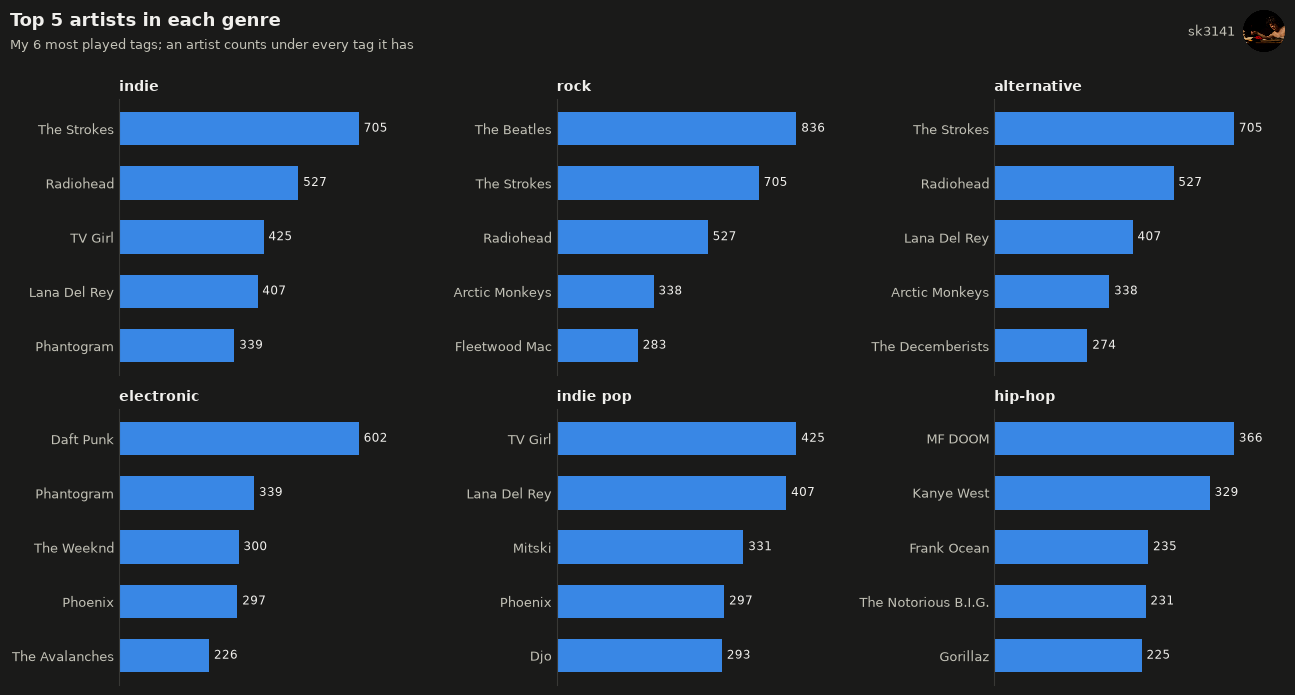

In [4]:
def short_name(name, limit=24):
    return name if len(name) <= limit else name[:limit - 1].rstrip() + '\u2026'


def plot_top_artists_by_genre(save=False):
    '''Small multiples: the top artists in each of the top genres, as horizontal bars.'''
    n_cols = 3
    n_rows = -(-len(genres) // n_cols)  # ceiling division
    row_height = 0.42 * TOP_N + 0.8  # room for the bars and the panel title
    height = row_height * n_rows + 1.2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, height), facecolor=SURFACE, squeeze=False)

    for ax, tag in zip(axes.flat, genres):
        top = top_artists_in(tag)
        ax.set_facecolor(SURFACE)
        positions = range(len(top))
        ax.barh(positions, top['plays'], color=BAR_COLOR, height=0.62)
        ax.set_yticks(positions, [short_name(name) for name in top['artist']])
        ax.invert_yaxis()  # most played on top
        ax.set_xlim(0, top['plays'].max() * 1.2)  # room for the value labels
        for y, plays in zip(positions, top['plays']):
            ax.text(plays + top['plays'].max() * 0.02, y, f'{plays:,}', va='center', fontsize=8.5, color=INK)

        ax.set_title(tag, loc='left', fontsize=10, fontweight='bold', color=INK)
        ax.set_xticks([])
        for side in ('top', 'right', 'bottom'):
            ax.spines[side].set_visible(False)
        ax.spines['left'].set_color(BASELINE)
        ax.tick_params(length=0, labelsize=9, labelcolor=INK_SECONDARY)

    for ax in axes.flat[len(genres):]:
        ax.set_visible(False)  # unused panels

    add_title(fig, f'Top {TOP_N} artists in each genre',
              f'My {len(genres)} most played tags; an artist counts under every tag it has', height)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.65 / height))
    if save:
        save_figure(fig, 'top_artists_by_genre')
    plt.show()


plot_top_artists_by_genre(save=True)